# 04-2. 결빙 분류: 고전 ML 기법 비교

04의 2장입니다. 04-1의 후보 외에 다른 고전 기법, MLP 구조, 앙상블을 같은 조건으로 비교합니다. 조건은 결빙관련 라벨, 같은 변수, 지점 단위 7묶음 교차검증, 일별 F1이 가장 높은 임계값입니다. 추가 자료(ERA5-Land 강수·강설, 서해 해기차)를 더했을 때의 기여도 재었습니다(2-3).

02-2의 지점 변수, 03-3의 추정 노면온도, 04-1의 교차검증 결과, 02-3의 `era5_10min.parquet`, `sea_10min.parquet`을 읽습니다. 결과 표는 `data/results/`에 저장합니다.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import itertools
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from cycler import cycler
from joblib import Parallel, delayed
from matplotlib import font_manager
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
SEED = 42

In [3]:
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet")
sf = sf.merge(pd.read_parquet(config.PROCESSED_DIR / "station_estimates.parquet"), on=["stn", "time"])
sf["rst_dpd"] = sf["rst_est"] - sf["td"]  # 추정 노면온도 - 이슬점 (04-1과 같음)
sf["date"] = sf["time"].dt.normalize()
cv = json.load(open(config.PROCESSED_DIR / "icing_cv.json", encoding="utf-8"))  # 04-1에서 정한 설정
CLS_FEATURES, folds, FINAL, INTERPRET = cv["features"], cv["folds"], cv["final"], cv["interpret"]
sf["related"] = sf["state"].isin(cv["related_states"]).astype("float32").where(sf["state"].notna())
train_all = sf[~sf["stn"].isin(config.HOLDOUT_STATIONS)].reset_index(drop=True)
stns = sorted(train_all["stn"].unique())

# 04-1의 학습 지점 교차검증 확률 (후보 3개)
oof_prob = pd.read_parquet(config.PROCESSED_DIR / "icing_oof.parquet")
assert oof_prob["stn"].equals(train_all["stn"]) and oof_prob["time"].equals(train_all["time"])
oof_prob = oof_prob.drop(columns=["stn", "time"])
print(f"학습 지점 {len(stns)}곳, 최종 모델: {FINAL}, 해석용 모델: {INTERPRET}")

학습 지점 14곳, 최종 모델: LightGBM(결빙관련 라벨), 해석용 모델: 로지스틱 회귀(결빙관련 라벨)


## 2. 고전 ML 기법 비교

LightGBM이 가장 좋은 방법인지 확인하려고 같은 22개 변수, 양성 가중치 5로 다른 기법을 비교했습니다. 이 절의 기법은 참고용이고 최종 후보에는 넣지 않았습니다.

| 기법 | 설정 |
|------|------|
| XGBoost | 깊이 4, 400회, 학습률 0.03 (LightGBM과 같은 부스팅 계열) |
| 스플라인 로지스틱 (GAM 근사) | 변수별 3차 스플라인(매듭 5개)을 만든 뒤 로지스틱 (C=0.05). 변수마다 비선형 효과를 허용 |
| Random Forest | 200그루, 잎 최소 50행, 그루마다 30% 표본 |
| Extra Trees | 200그루, 잎 최소 50행, 무작위 분할 |
| MLP | 은닉층 32-16 (ReLU), L2 1e-3, 조기 종료. 표준화 입력 |

In [4]:
POS_W = 5


def imputed(*steps):
    return make_pipeline(SimpleImputer(strategy="median"), *steps)


OTHER_MODELS = {
    "XGBoost": lambda: xgb.XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=4, min_child_weight=50,
                                         subsample=0.7, colsample_bytree=0.7, reg_lambda=5.0, scale_pos_weight=POS_W,
                                         tree_method="hist", n_jobs=4, random_state=SEED),
    "스플라인 로지스틱(GAM)": lambda: imputed(SplineTransformer(n_knots=5, extrapolation="linear"), StandardScaler(),
                                      LogisticRegression(C=0.05, class_weight={0: 1, 1: POS_W}, max_iter=3000)),
    "Random Forest": lambda: imputed(RandomForestClassifier(n_estimators=200, min_samples_leaf=50, max_features="sqrt",
                                                            max_samples=0.3, class_weight={0: 1, 1: POS_W},
                                                            n_jobs=-1, random_state=SEED)),
    "Extra Trees": lambda: imputed(ExtraTreesClassifier(n_estimators=200, min_samples_leaf=50, max_features=0.5,
                                                        max_samples=0.3, bootstrap=True, class_weight={0: 1, 1: POS_W},
                                                        n_jobs=-1, random_state=SEED)),
    "MLP(32-16)": lambda: imputed(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3,
                                                                  early_stopping=True, max_iter=80, batch_size=512,
                                                                  random_state=SEED)),
}


def fit_related(make, df):
    """결빙관련 라벨로 학습한다. MLP는 class_weight가 없어 양성 표본 가중치로 같은 효과를 준다."""
    d = df.dropna(subset=["related"])
    y = d["related"].astype(int)
    m = make()
    if hasattr(m, "steps") and isinstance(m[-1], MLPClassifier):
        return m.fit(d[CLS_FEATURES], y, mlpclassifier__sample_weight=np.where(y == 1, POS_W, 1.0))
    return m.fit(d[CLS_FEATURES], y)


def oof_related(make):
    prob = np.full(len(train_all), np.nan)
    for val_stns in folds:
        va = train_all["stn"].isin(val_stns).to_numpy()
        prob[va] = fit_related(make, train_all[~va]).predict_proba(train_all.loc[va, CLS_FEATURES])[:, 1]
    return prob


cmp_prob = pd.DataFrame({"LightGBM(결빙관련 라벨)": oof_prob["LightGBM(결빙관련 라벨)"],
                         "로지스틱 회귀(결빙관련 라벨)": oof_prob["로지스틱 회귀(결빙관련 라벨)"]})
cmp_time = {}
for name, make in OTHER_MODELS.items():
    t0 = time.time()
    cmp_prob[name] = oof_related(make)
    cmp_time[name] = time.time() - t0
    print(f"{name}: {cmp_time[name]:.0f}s")

XGBoost: 24s


스플라인 로지스틱(GAM): 99s


Random Forest: 77s


Extra Trees: 48s


MLP(32-16): 117s


모델 간 일별 F1 차이가 우연인지 보려고 날짜 단위 부트스트랩(1,000회)으로 차이의 95% 구간을 구했습니다. 같은 날의 여러 지점은 같은 기상을 겪으므로 날짜를 통째로 다시 뽑습니다. 계산을 빠르게 하려고 일별 F1을 지점-날 단위 배열로 미리 만들었습니다.

In [5]:
lab_rows = train_all["ice"].notna().to_numpy()
stn_pos = {s: i for i, s in enumerate(stns)}
day_key, _ = pd.factorize(train_all.loc[lab_rows, "stn"].astype(str) + "_"
                          + train_all.loc[lab_rows, "time"].dt.strftime("%Y%m%d"))
day_stn = np.zeros(day_key.max() + 1, int)
day_stn[day_key] = train_all.loc[lab_rows, "stn"].map(stn_pos).to_numpy()
day_date = np.zeros(day_key.max() + 1, int)
day_date[day_key] = pd.factorize(train_all.loc[lab_rows, "time"].dt.normalize())[0]
y_lab = train_all.loc[lab_rows, "ice"].astype(int).to_numpy()
stn_has_ice = np.bincount(day_stn, np.bincount(day_key, y_lab), len(stns)) > 0  # 실제 결빙이 없는 지점은 평균에서 뺀다


def day_f1(pred):
    """지점-날별 (F1, 평가 여부). 평가 = 그날 실제·예측 결빙이 하나라도 있음 (빈 날 제외 방식)."""
    p = np.asarray(pred)[lab_rows].astype(int)
    tp = np.bincount(day_key, y_lab & p)
    fp = np.bincount(day_key, (1 - y_lab) & p)
    fn = np.bincount(day_key, y_lab & (1 - p))
    den = 2 * tp + fp + fn
    return np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0), den > 0


def mean_daily_f1(f1, ev, station_idx=None, date_w=None):
    """실제 결빙이 있는 지점의 평가일 평균 → 지점 평균 (daily_f1과 같은 값). date_w: 날짜별 부트스트랩 가중치."""
    w = ev * (1.0 if date_w is None else date_w[day_date])
    s_sum = np.bincount(day_stn, f1 * w, len(stns))
    s_n = np.bincount(day_stn, w, len(stns))
    per = np.where((s_n > 0) & stn_has_ice, s_sum / np.where(s_n > 0, s_n, 1), np.nan)
    return np.nanmean(per if station_idx is None else per[station_idx])


def best_thr_fast(score_vec, station_idx=None):
    cands = np.unique(np.quantile(score_vec[~np.isnan(score_vec)], (0.95, 0.98, 0.99, 0.995, 0.998, 0.999, 0.9995, 0.9998)))
    vals = [mean_daily_f1(*day_f1(score_vec >= t), station_idx) for t in cands]
    return cands[int(np.argmax(vals))], max(vals)


related_ok = train_all["related"].notna().to_numpy()
rows = []
day_scores = {}
for name in cmp_prob:
    prob = cmp_prob[name].to_numpy()
    thr, f1 = best_thr_fast(prob)
    day_scores[name] = day_f1(prob >= thr)
    rows.append({"방법": name, "AP(Ice)": average_precision_score(y_lab, prob[lab_rows]),
                 "AP(결빙관련)": average_precision_score(train_all.loc[related_ok, "related"], prob[related_ok]),
                 "일별 F1 (빈 날 제외)": f1, "Ice 포착률(10분)": (prob >= thr)[lab_rows][y_lab == 1].mean(),
                 "결빙 판정 비율": (prob >= thr).mean(), "학습 시간(s)": cmp_time.get(name, np.nan)})
cmp_table = pd.DataFrame(rows).set_index("방법")

n_dates = day_date.max() + 1
rng = np.random.default_rng(SEED)
boot_w = np.stack([np.bincount(rng.integers(0, n_dates, n_dates), minlength=n_dates) for _ in range(1000)])
ref = FINAL if FINAL in cmp_prob else "LightGBM(결빙관련 라벨)"
ref_boot = np.array([mean_daily_f1(*day_scores[ref], date_w=w) for w in boot_w])
for name in cmp_prob:
    diff = np.array([mean_daily_f1(*day_scores[name], date_w=w) for w in boot_w]) - ref_boot
    cmp_table.loc[name, f"{ref} 대비 차이"] = cmp_table.loc[name, "일별 F1 (빈 날 제외)"] - cmp_table.loc[ref, "일별 F1 (빈 날 제외)"]
    cmp_table.loc[name, "95% 구간"] = f"[{np.quantile(diff, 0.025):+.4f}, {np.quantile(diff, 0.975):+.4f}]"
print("참고: Ice 비율(무작위 예측의 AP) =", round(y_lab.mean(), 5))
cmp_table.sort_values("일별 F1 (빈 날 제외)", ascending=False).round(4)

참고: Ice 비율(무작위 예측의 AP) = 0.0005


,AP(Ice),AP(결빙관련),일별 F1 (빈 날 제외),Ice 포착률(10분),결빙 판정 비율,학습 시간(s),LightGBM(결빙관련 라벨) 대비 차이,95% 구간
방법,,,,,,,,
스플라인 로지스틱(GAM),0.0126,0.4687,0.0425,0.0837,0.002,98.9087,0.0158,"[-0.0166, +0.0758]"
Random Forest,0.0099,0.4825,0.0386,0.2552,0.010,76.6817,0.0118,"[+0.0010, +0.0266]"
로지스틱 회귀(결빙관련 라벨),0.0112,0.4481,0.0367,0.2301,0.010,NaN,0.0099,"[-0.0111, +0.0420]"
MLP(32-16),0.0100,0.4444,0.0361,0.0586,0.002,116.6144,0.0093,"[-0.0264, +0.0611]"
Extra Trees,0.0095,0.4860,0.0301,0.2510,0.010,48.4806,0.0033,"[-0.0070, +0.0151]"
XGBoost,0.0117,0.4794,0.0285,0.2469,0.010,24.4919,0.0017,"[-0.0028, +0.0066]"
LightGBM(결빙관련 라벨),0.0111,0.4744,0.0268,0.2636,0.010,NaN,0.0000,"[+0.0000, +0.0000]"


7개 기법의 일별 F1은 0.027~0.043이고 AP(Ice)는 0.0095~0.0126입니다. 무작위 예측 AP 0.0005의 19~25배입니다.

LightGBM 대비 일별 F1 차이의 95% 구간은 Random Forest만 0보다 위에 있고([+0.001, +0.027]) 나머지는 0을 포함합니다. 로지스틱 +0.010 [-0.011, +0.042], 스플라인 로지스틱 +0.016 [-0.017, +0.076], XGBoost +0.002 [-0.003, +0.007]입니다. Random Forest의 구간도 여섯 번 비교한 것 중 하나이고, 임계값을 같은 자료로 골랐으며, 기준인 LightGBM 0.0268은 시드 3개 중 가장 낮은 값입니다(2-3). 그래서 어느 기법이 낫다고 결론 내리지 않았습니다.

지표마다 1위도 다릅니다. 일별 F1과 AP(Ice)는 스플라인 로지스틱, AP(결빙관련)는 Extra Trees가 가장 높습니다. 04-1의 0절에서 실제 노면상태를 알아도 일별 F1이 0.1 수준이었던 만큼 성능은 기법보다 라벨에 묶여 있습니다.

### 2-1. MLP 구조 실험

은닉층 너비(16~256), 깊이(1~4층), L2 규제, 활성화 함수, 시드 평균을 바꿔 같은 교차검증으로 비교했습니다. 모두 표준화 입력, Adam, 미니배치 512이고 학습 자료 10%로 조기 종료합니다.

In [6]:
MLP_ARCHS = [
    ("1층 16", (16,), {}), ("1층 64", (64,), {}), ("1층 256", (256,), {}),
    ("2층 32-16", (32, 16), {}), ("2층 64-64", (64, 64), {}), ("2층 256-256", (256, 256), {}),
    ("3층 128-64-32", (128, 64, 32), {}), ("4층 256-128-64-32", (256, 128, 64, 32), {}),
    ("2층 32-16, L2 0.1", (32, 16), {"alpha": 0.1}), ("2층 32-16, L2 1", (32, 16), {"alpha": 1.0}),
    ("2층 32-16, tanh", (32, 16), {"activation": "tanh"}),
    ("2층 32-16, 시드 5개 평균", (32, 16), {"seeds": 5}),
]


def mlp_fold(data, hidden, opt, val_stns, seed):
    """한 묶음의 MLP 학습·예측 (7묶음 병렬, 묶음당 BLAS 2스레드). 반환: (검증 행 마스크, 확률)."""
    warnings.filterwarnings("ignore", category=UserWarning)
    with threadpool_limits(2):
        va = data["stn"].isin(val_stns).to_numpy()
        make = lambda: imputed(StandardScaler(), MLPClassifier(  # noqa: E731
            hidden_layer_sizes=hidden, alpha=opt.get("alpha", 1e-3), activation=opt.get("activation", "relu"),
            early_stopping=True, max_iter=80, batch_size=512, random_state=seed))
        return va, fit_related(make, data[~va]).predict_proba(data.loc[va, CLS_FEATURES])[:, 1]


mlp_rows, mlp_prob = [], {}
mlp_data = train_all[["stn", "related"] + CLS_FEATURES]
for name, hidden, opt in MLP_ARCHS:
    t0 = time.time()
    outs = Parallel(n_jobs=7)(delayed(mlp_fold)(mlp_data, hidden, opt, v, SEED + k)
                              for k in range(opt.get("seeds", 1)) for v in folds)
    acc, cnt = np.zeros(len(train_all)), np.zeros(len(train_all))
    for va, p in outs:
        acc[va] += p
        cnt[va] += 1
    prob = acc / np.maximum(cnt, 1)
    mlp_prob[name] = prob
    n_params = sum(a * b for a, b in zip((len(CLS_FEATURES),) + hidden, hidden + (1,))) + sum(hidden) + 1
    mlp_rows.append({"구조": name, "층 수": len(hidden), "매개변수 수": n_params,
                     "AP(Ice)": average_precision_score(y_lab, prob[lab_rows]),
                     "AP(결빙관련)": average_precision_score(train_all.loc[related_ok, "related"], prob[related_ok]),
                     "일별 F1 (빈 날 제외)": best_thr_fast(prob)[1], "학습 시간(s)": time.time() - t0})
    print(f"{name}: {time.time() - t0:.0f}s")
mlp_table = pd.DataFrame(mlp_rows).set_index("구조")
mlp_table.round(4)

1층 16: 16s


1층 64: 43s


1층 256: 86s


2층 32-16: 32s


2층 64-64: 50s


2층 256-256: 285s


... (3 outputs left out)

2층 32-16, L2 1: 27s


2층 32-16, tanh: 20s


2층 32-16, 시드 5개 평균: 165s


,층 수,매개변수 수,AP(Ice),AP(결빙관련),일별 F1 (빈 날 제외),학습 시간(s)
구조,,,,,,
1층 16,1,385,0.0167,0.4956,0.0416,15.8215
1층 64,1,1537,0.0104,0.4579,0.0319,42.7113
1층 256,1,6145,0.0104,0.4543,0.0368,86.0292
2층 32-16,2,1281,0.0100,0.4444,0.0361,32.2164
2층 64-64,2,5697,0.0099,0.4550,0.0228,50.2015
2층 256-256,2,71937,0.0076,0.3809,0.0215,285.2114
3층 128-64-32,3,13313,0.0082,0.3944,0.0205,120.9480
4층 256-128-64-32,4,49153,0.0073,0.3969,0.0236,243.0568
"2층 32-16, L2 0.1",2,1281,0.0097,0.4847,0.0289,27.4965


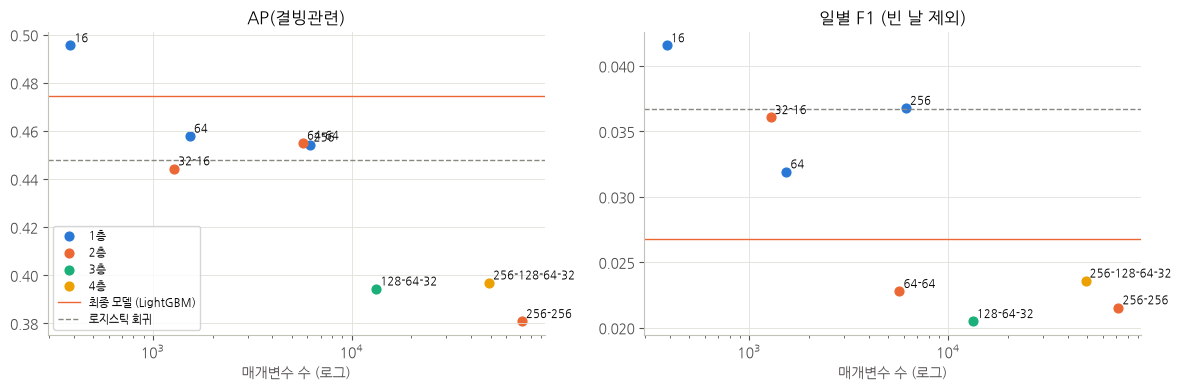

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plain = mlp_table[~mlp_table.index.str.contains(",")]
for ax, col in zip(axes, ["AP(결빙관련)", "일별 F1 (빈 날 제외)"]):
    for depth, g in plain.groupby("층 수"):
        ax.scatter(g["매개변수 수"], g[col], s=40, label=f"{depth}층")
        for name, r in g.iterrows():
            ax.annotate(name.split(" ")[1], (r["매개변수 수"], r[col]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.axhline(cmp_table.loc[FINAL, col], color="#eb6834", linewidth=1, label="최종 모델 (LightGBM)")
    ax.axhline(cmp_table.loc[INTERPRET, col], color="#898781", linewidth=1, linestyle="--", label="로지스틱 회귀")
    ax.set_xscale("log")
    ax.set_xlabel("매개변수 수 (로그)")
    ax.set_title(col)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

크고 깊을수록 결빙관련 AP가 낮습니다(1층 16개 0.4956, 2층 256-256 0.3809, 3층 128-64-32 0.3944, 4층 256-128-64-32 0.3969). 노면온도 추정(03-2의 3-2)과 같은 양상입니다. 결빙관련 AP가 가장 높은 구조는 강한 규제(L2 1)를 건 2층 32-16(0.4984)입니다. 2층 32-16을 시드 5개로 평균하면 결빙관련 AP가 0.4444에서 0.4849로, 일별 F1이 0.0361에서 0.0434로 오릅니다. 규제와 평균처럼 분산을 줄이는 쪽이 도움이 됐습니다.

1층 16개는 AP(Ice) 0.0167로 표에서 가장 높지만 12가지 가운데 시드 하나의 값입니다. LightGBM(AP(결빙관련) 0.4744, 일별 F1 0.0268)이나 로지스틱(0.4481, 0.0367)과 비교해도 같은 수준이라 MLP는 후보에 넣지 않았습니다.

### 2-2. 앙상블 실험

서로 다른 모델의 확률을 합치면 나아지는지 봤습니다. 모델마다 확률의 크기가 달라서 순위 평균(각 모델 확률을 0~1 백분위로 바꿔 평균)을 씁니다. 후보는 위 7개 모델의 2~4개 조합 전부입니다.

같은 교차검증 결과로 조합을 고르면 점수가 부풀려집니다. 그래서 중첩 교차검증 점수도 냈습니다. 7묶음마다 나머지 12개 지점만으로 조합과 임계값을 고르고 그 묶음 지점에 적용합니다.

In [8]:
ENS_POOL = list(cmp_prob.columns)
ranks = cmp_prob.rank(pct=True).to_numpy()
subsets = [c for k in range(1, 5) for c in itertools.combinations(range(len(ENS_POOL)), k)]
sub_score = {c: ranks[:, list(c)].mean(axis=1) for c in subsets}
sub_f1 = {c: best_thr_fast(v)[1] for c, v in sub_score.items()}
ens_top = pd.DataFrame([{"조합": " + ".join(ENS_POOL[i] for i in c), "모델 수": len(c), "일별 F1 (빈 날 제외)": f1,
                         "AP(Ice)": average_precision_score(y_lab, sub_score[c][lab_rows])}
                        for c, f1 in sorted(sub_f1.items(), key=lambda kv: -kv[1])[:10]])
print("조합 크기별 최고 일별 F1 (같은 교차검증으로 고름, 낙관적):",
      {k: round(max(v for c, v in sub_f1.items() if len(c) == k), 4) for k in range(1, 5)})
ens_top.round(4)

조합 크기별 최고 일별 F1 (같은 교차검증으로 고름, 낙관적): {1: np.float64(0.0425), 2: np.float64(0.0441), 3: np.float64(0.0442), 4: np.float64(0.047)}


,조합,모델 수,일별 F1 (빈 날 제외),AP(Ice)
0,로지스틱 회귀(결빙관련 라벨) + 스플라인 로지스틱(GAM) + Random For...,4,0.0470,0.0115
1,LightGBM(결빙관련 라벨) + 로지스틱 회귀(결빙관련 라벨) + Random ...,3,0.0442,0.0118
2,Random Forest + MLP(32-16),2,0.0441,0.0102
3,로지스틱 회귀(결빙관련 라벨) + XGBoost + Random Forest + E...,4,0.0436,0.0112
4,LightGBM(결빙관련 라벨) + 로지스틱 회귀(결빙관련 라벨),2,0.0435,0.0131
5,로지스틱 회귀(결빙관련 라벨) + XGBoost + Random Forest,3,0.0429,0.0120
6,스플라인 로지스틱(GAM),1,0.0425,0.0126
7,LightGBM(결빙관련 라벨) + 로지스틱 회귀(결빙관련 라벨) + Random ...,4,0.0420,0.0112
8,스플라인 로지스틱(GAM) + Random Forest + Extra Trees,3,0.0416,0.0114
9,로지스틱 회귀(결빙관련 라벨) + XGBoost + Extra Trees,3,0.0406,0.0120


In [9]:
def nested_daily_f1(candidates):
    """묶음마다 나머지 지점으로 조합·임계값을 고르고 묶음에 적용한 예측의 일별 F1."""
    pred, picks = np.zeros(len(train_all), bool), []
    for val_stns in folds:
        tr_idx = np.array([stn_pos[s] for s in stns if s not in val_stns])
        best = max(candidates, key=lambda c: best_thr_fast(sub_score[c], tr_idx)[1])
        thr, _ = best_thr_fast(sub_score[best], tr_idx)
        va = train_all["stn"].isin(val_stns).to_numpy()
        pred[va] = sub_score[best][va] >= thr
        picks.append(" + ".join(ENS_POOL[i] for i in best))
    return mean_daily_f1(*day_f1(pred)), pd.Series(picks).value_counts().to_dict()


def fixed(*names):
    return [tuple(sorted(ENS_POOL.index(n) for n in names))]


NESTED = {
    "LightGBM 고정 (최종 모델)": fixed("LightGBM(결빙관련 라벨)"),
    "로지스틱 고정": fixed("로지스틱 회귀(결빙관련 라벨)"),
    "LightGBM + 로지스틱 순위 평균 고정": fixed("LightGBM(결빙관련 라벨)", "로지스틱 회귀(결빙관련 라벨)"),
    "7개 전체 순위 평균 고정": [tuple(range(len(ENS_POOL)))],
    "단일 모델 선택 (중첩)": [c for c in subsets if len(c) == 1],
    "조합 선택 2~4개 (중첩)": [c for c in subsets if len(c) >= 2],
}
for c in NESTED["7개 전체 순위 평균 고정"]:
    sub_score[c] = ranks.mean(axis=1)
nested_rows = []
for name, cand in NESTED.items():
    f1, picks = nested_daily_f1(cand)
    nested_rows.append({"방법": name, "일별 F1 (빈 날 제외, 정직)": f1,
                        "묶음별 선택": "; ".join(f"{k} ({v}회)" for k, v in picks.items()) if len(cand) > 1 else ""})
pd.DataFrame(nested_rows).set_index("방법").round(4)

,"일별 F1 (빈 날 제외, 정직)",묶음별 선택
방법,,
LightGBM 고정 (최종 모델),0.0174,
로지스틱 고정,0.0367,
LightGBM + 로지스틱 순위 평균 고정,0.0435,
7개 전체 순위 평균 고정,0.0254,
단일 모델 선택 (중첩),0.0083,스플라인 로지스틱(GAM) (6회); MLP(32-16) (1회)
조합 선택 2~4개 (중첩),0.0087,로지스틱 회귀(결빙관련 라벨) + 스플라인 로지스틱(GAM) + Random For...


같은 교차검증으로 고르면 4개 조합이 0.0470으로 가장 높아 보입니다. 고르는 과정까지 중첩으로 평가하면 조합 선택은 0.0087, 단일 모델 선택은 0.0083으로 내려갑니다. 묶음마다 고른 조합이 달랐습니다.

표의 모든 행은 임계값을 묶음 밖에서 고른 값입니다. 고정 행도 모델만 고정하고 임계값은 같은 방식으로 고릅니다. 고정 조합 중에서는 LightGBM + 로지스틱 순위 평균이 0.0435(AP(Ice) 0.0131)로 가장 높고, 로지스틱 단독 0.0367, 7개 전체 0.0254, LightGBM 단독 0.0174입니다. LightGBM은 임계값을 14곳 전체로 고르면 0.0268이어서 임계값 선택의 영향이 큽니다.

LightGBM 시드를 5개로 늘려 보면 순위 평균의 일별 F1은 0.027~0.044(평균 0.033)이고 AP(Ice)는 0.0116~0.0135(평균 0.0126)입니다. 로지스틱 단독(0.0367, 0.0112)과 비교해 일별 F1은 구분되지 않고 AP(Ice)는 조금 높습니다(`scripts/check_icing_models.py`).

앙상블은 쓰지 않았습니다. 순위를 새 지점과 구간에 적용하려면 기준 분포를 따로 둬야 하고 실시간 추정도 복잡해집니다. 이득이 일별 F1의 흔들림을 넘지 못한다고 봤습니다.

### 2-3. 추가 자료 기여: ERA5-Land 강수·강설, 서해 해기차

이 지역 Ice의 81%는 강수 중이거나 강수 직후에 나왔습니다(01-6의 13장). 지금 변수의 수분 정보는 AWS 강수 감지·강수량(`rain`, `pr60`, `pr12h`, `rain_hrs12h`, `hrs_since_rain`)과 ASOS 적설(`snow`)입니다. 지금 내리는 것이 눈인지 비인지를 나타내는 변수는 없습니다. ERA5-Land(02-3)는 격자(약 9km)마다 강수와 강설(물 환산)을 나누어 줍니다. 그래서 지난 3시간 강수 합, 강설 합, 강설 비율 3개를 더해 봤습니다. 해기차는 `sea_dT_c_A`, `sea_dT_c_B`, `sea_wind850_dir_deg_A`, `sea_wind850_speed_ms_A` 4개입니다.

모델은 04-1의 두 후보(LightGBM, 로지스틱 회귀, 결빙관련 라벨)를 같은 설정으로 다시 학습합니다. 지표는 AP(Ice), AP(결빙관련), 일별 F1과 일별 F1 차이의 날짜 단위 부트스트랩 95% 구간입니다. 다른 겨울 AP는 다른 지점의 다른 겨울로만 학습한 값입니다. 해기차처럼 모든 지점에 같은 시계열은 같은 시각의 신호를 다른 지점에서 옮겨 올 수 있어서 이 평가를 더했습니다. 검증 지점은 쓰지 않았습니다.

In [10]:
import lightgbm as lgb

LGB_PARAMS = dict(objective="binary", learning_rate=0.03, n_estimators=400, num_leaves=15, min_child_samples=200,
                  subsample=0.7, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0, n_jobs=-1, verbose=-1)  # 04-1과 같은 설정


def make_lgb(seed=SEED):
    return lgb.LGBMClassifier(**LGB_PARAMS, random_state=seed, scale_pos_weight=POS_W)


def make_logit():
    return imputed(StandardScaler(), LogisticRegression(C=0.1, class_weight={0: 1, 1: POS_W}, max_iter=2000))


E5_MODELS = {"LightGBM(결빙관련 라벨)": make_lgb, "로지스틱 회귀(결빙관련 라벨)": make_logit}
ERA5_FEATURES = ["era5_tp3h", "era5_sf3h", "era5_snowfrac3h"]
SEA_FEATURES = ["sea_dT_c_A", "sea_dT_c_B", "sea_wind850_dir_deg_A", "sea_wind850_speed_ms_A"]
EXTRA_SETS = {f"04-1 변수 {len(CLS_FEATURES)}개": [], "+ ERA5 강수·강설 3개": ERA5_FEATURES, "+ 해기차 4개": SEA_FEATURES,
              "+ ERA5 + 해기차": ERA5_FEATURES + SEA_FEATURES}
era5 = pd.read_parquet(config.PROCESSED_DIR / "era5_10min.parquet", columns=["stn", "time", "tp3h", "sf3h", "snowfrac3h"])
sea = pd.read_parquet(config.PROCESSED_DIR / "sea_10min.parquet", columns=["time", *SEA_FEATURES])
e5 = (train_all[["stn", "time"]].merge(era5, on=["stn", "time"], how="left", validate="one_to_one")
      .merge(sea, on="time", how="left", validate="many_to_one"))
train_e5 = train_all.assign(**{f"era5_{c}": e5[c].to_numpy() for c in ["tp3h", "sf3h", "snowfrac3h"]},
                            **{c: e5[c].to_numpy() for c in SEA_FEATURES})
print("외부 변수가 빈 행:", int(train_e5[ERA5_FEATURES + SEA_FEATURES].isna().any(axis=1).sum()))
second_winter = (train_e5["time"] >= pd.Timestamp(config.PERIODS[1][0])).to_numpy()


def fit_extra(make, rows, feats):
    d = train_e5[rows & related_ok]
    return make().fit(d[feats], d["related"].astype(int))


def cv_prob(make, feats):
    """지점 단위 7묶음 교차검증 확률."""
    prob = np.full(len(train_e5), np.nan)
    for val_stns in folds:
        va = train_e5["stn"].isin(val_stns).to_numpy()
        prob[va] = fit_extra(make, ~va, feats).predict_proba(train_e5.loc[va, feats])[:, 1]
    return prob


def other_winter_prob(make, feats):
    """다른 지점의 다른 겨울로만 학습한 확률. 같은 시각의 신호를 다른 지점에서 옮겨 올 수 없다."""
    prob = np.full(len(train_e5), np.nan)
    for val_stns in folds:
        va = train_e5["stn"].isin(val_stns).to_numpy()
        for w in (False, True):
            test = va & (second_winter == w)
            prob[test] = fit_extra(make, ~va & (second_winter != w), feats).predict_proba(train_e5.loc[test, feats])[:, 1]
    return prob


def ap_scores(prob, prefix=""):
    return {f"{prefix}AP(Ice)": average_precision_score(y_lab, prob[lab_rows]),
            f"{prefix}AP(결빙관련)": average_precision_score(train_all.loc[related_ok, "related"], prob[related_ok])}


all_rows = np.ones(len(train_e5), bool)
e5_rows, t0 = [], time.time()
for name, make in E5_MODELS.items():
    for set_name, extra in EXTRA_SETS.items():
        feats = CLS_FEATURES + extra
        prob = cv_prob(make, feats) if extra else cmp_prob[name].to_numpy()
        thr, f1 = best_thr_fast(prob)
        days = day_f1(prob >= thr)
        diff = np.array([mean_daily_f1(*days, date_w=w) - mean_daily_f1(*day_scores[name], date_w=w) for w in boot_w])
        e5_rows.append({"모델": name, "변수": set_name, **ap_scores(prob), **ap_scores(other_winter_prob(make, feats), "다른 겨울 "),
                        "일별 F1 (빈 날 제외)": f1, "일별 F1 차이": f1 - cmp_table.loc[name, "일별 F1 (빈 날 제외)"] if extra else np.nan,
                        "95% 구간": f"[{np.quantile(diff, 0.025):+.4f}, {np.quantile(diff, 0.975):+.4f}]" if extra else ""})
    print(f"{name}: {time.time() - t0:.0f}s")
era5_table = pd.DataFrame(e5_rows).set_index(["모델", "변수"])
era5_table.round(4)


외부 변수가 빈 행: 0


LightGBM(결빙관련 라벨): 278s


로지스틱 회귀(결빙관련 라벨): 508s


AP(Ice)  AP(결빙관련)  다른 겨울 AP(Ice)  다른 겨울 AP(결빙관련)  일별 F1 (빈 날 제외)  일별 F1 차이              95% 구간
모델                변수                                                                                                             
LightGBM(결빙관련 라벨) 04-1 변수 22개       0.0111    0.4744         0.0099          0.3605          0.0268       NaN                    
                  + ERA5 강수·강설 3개   0.0118    0.4658         0.0091          0.3463          0.0327    0.0059  [-0.0077, +0.0240]
                  + 해기차 4개          0.0106    0.4900         0.0108          0.3707          0.0321    0.0054  [-0.0005, +0.0125]
                  + ERA5 + 해기차      0.0117    0.4853         0.0103          0.3682          0.0313    0.0045  [-0.0019, +0.0128]
로지스틱 회귀(결빙관련 라벨)  04-1 변수 22개       0.0112    0.4481         0.0075          0.3308          0.0367       NaN                    
                  + ERA5 강수·강설 3개   0.0107    0.4728         0.0076          0.3717          0.0338   -0.0029  [-0.0293, +0.0455]
                  + 해기차 4개          0.0097    0.4975         0.0076          0.4007          0.0303   -0.0064  [-0.0229, +0.0057]
                  + ERA5 + 해기차      0.0099    0.4981         0.0072          0.4516          0.0318   -0.0049  [-0.0242, +0.0096]

LightGBM은 시드에 따라 값이 흔들려서 시드 3개로 다시 쟀습니다. 외부 변수의 몫은 학습 지점 전체로 학습한 모델로 봅니다.

In [11]:
seed_rows = []
for seed in (SEED, 1, 2):
    for set_name, extra in EXTRA_SETS.items():
        feats = CLS_FEATURES + extra
        prob = cv_prob(lambda: make_lgb(seed), feats)
        seed_rows.append({"시드": seed, "변수": set_name, **ap_scores(prob), "일별 F1 (빈 날 제외)": best_thr_fast(prob)[1],
                          **ap_scores(other_winter_prob(lambda: make_lgb(seed), feats), "다른 겨울 ")})
seed_table = pd.DataFrame(seed_rows).drop(columns="시드").groupby("변수", sort=False).agg(["mean", "min", "max"])
print(f"LightGBM 시드 3개 ({time.time() - t0:.0f}s)")
share = {}
for set_name, extra in list(EXTRA_SETS.items())[1:]:
    feats = CLS_FEATURES + extra
    gain = pd.Series(fit_extra(make_lgb, all_rows, feats).booster_.feature_importance("gain"), index=feats)
    share[set_name] = gain[extra].sum() / gain.sum()
coef = pd.Series(fit_extra(make_logit, all_rows, CLS_FEATURES + ERA5_FEATURES)[-1].coef_[0][-3:], index=ERA5_FEATURES)
print("LightGBM 정보 이득 중 외부 변수의 몫:", {k: round(v, 3) for k, v in share.items()})
print("로지스틱 표준화 계수:", coef.round(3).to_dict())
seed_table.xs("mean", axis=1, level=1).round(4)


LightGBM 시드 3개 (1265s)


LightGBM 정보 이득 중 외부 변수의 몫: {'+ ERA5 강수·강설 3개': np.float64(0.355), '+ 해기차 4개': np.float64(0.046), '+ ERA5 + 해기차': np.float64(0.407)}
로지스틱 표준화 계수: {'era5_tp3h': -1.0449999570846558, 'era5_sf3h': 0.36800000071525574, 'era5_snowfrac3h': 0.1720000058412552}


,AP(Ice),AP(결빙관련),일별 F1 (빈 날 제외),다른 겨울 AP(Ice),다른 겨울 AP(결빙관련)
변수,,,,,
04-1 변수 22개,0.0107,0.4677,0.0318,0.0098,0.3594
+ ERA5 강수·강설 3개,0.0119,0.4664,0.0318,0.0093,0.3476
+ 해기차 4개,0.0108,0.4855,0.0334,0.0103,0.3723
+ ERA5 + 해기차,0.0117,0.4856,0.0347,0.0106,0.3757


ERA5 강수·강설을 더하면 AP(Ice)가 조금 오르고 다른 겨울 평가는 내려갑니다. LightGBM 시드 평균으로 AP(Ice)는 0.0107에서 0.0119, AP(결빙관련)은 0.4677에서 0.4664, 일별 F1은 0.0318로 같습니다. 다른 겨울 AP는 0.0098에서 0.0093, 0.3594에서 0.3476입니다. 로지스틱은 AP(결빙관련)이 0.4481에서 0.4728로 오르고 AP(Ice)는 0.0112에서 0.0107로 내려갑니다.

해기차를 더하면 결빙관련 AP가 오르고 Ice AP는 거의 그대로입니다. LightGBM 시드 평균으로 AP(결빙관련)은 0.4855, 다른 겨울 0.3723이고 AP(Ice)는 0.0108, 다른 겨울 0.0103입니다. 로지스틱의 다른 겨울 AP(결빙관련)은 0.3308에서 0.4007로 오르고 AP(Ice)는 0.0075에서 0.0076입니다.

둘 다 더하면 LightGBM 시드 평균의 AP 네 지표가 모두 오릅니다(0.0117, 0.4856, 0.0106, 0.3757). 일별 F1은 0.0347입니다. 일별 F1 차이의 95% 구간은 여섯 경우 모두 0을 포함합니다.

모델은 더한 변수를 많이 씁니다. LightGBM 정보 이득에서 차지하는 몫은 ERA5 3개 35.5%, 해기차 4개 4.6%, 둘 다 40.7%입니다. ERA5를 더한 로지스틱의 표준화 계수는 강수 -1.05, 강설 +0.37, 강설 비율 +0.17입니다. 강설이 같다면 강수가 많을수록(비가 섞일수록) 결빙관련 노면이 줄어드는 방향입니다.

최종 결빙 분류 모델에는 넣지 않고 22개 변수를 유지했습니다. 일별 F1이 구분되지 않고 Ice AP도 거의 그대로입니다. ERA5는 공개까지 며칠이 걸려 실시간 추정에 쓸 수도 없습니다. ERA5 강설은 05-1의 영향인자와 05-2의 M3로, 해기차는 05-1의 시간 지표로 씁니다.

### 2-4. 정리

| 실험 | 결과 | 판단 |
|------|------|------|
| 다른 고전 기법 (2절) | 일별 F1 0.027~0.043, AP(Ice) 0.0095~0.0126. LightGBM과의 차이 구간은 Random Forest 외에 모두 0 포함 | 어느 기법이 낫다고 할 수 없음 |
| MLP 구조 12가지 (2-1) | 작고 규제가 강할수록 결빙관련 AP가 높음 (최고 0.4984) | 쓰지 않음 |
| 앙상블 (2-2) | 선택 포함 중첩 점수 0.0083~0.0087, 고정 순위 평균 0.0435 (시드 5개 평균 0.033) | 쓰지 않음 |
| ERA5-Land, 해기차 (2-3) | AP 소폭 상승, 일별 F1 차이 구간은 모두 0 포함 | 최종 모델에 넣지 않음. 05의 영향인자, 기상 지표, 시간 지표로 사용 |

최종 모델은 LightGBM(결빙관련 라벨)이고 로지스틱 회귀는 해석용으로 함께 제시합니다(선택 근거는 04-1의 1장). 결빙 분류의 성능은 10분 단위로 깜빡이는 Ice 라벨, 제빙제 영향 코드, 학습 지점 수에 묶여 있습니다.

## 저장

`data/results/`에 저장합니다. `icing_model_comparison.csv`, `icing_mlp_architectures.csv`, `icing_ensembles.csv`는 기법 비교, MLP 구조, 앙상블 결과입니다. `icing_era5_ablation.csv`, `icing_external_seeds.csv`는 2-3의 교차검증 비교와 시드 3개 결과입니다.

In [12]:
cmp_table.round(4).to_csv(config.RESULT_DIR / "icing_model_comparison.csv", encoding="utf-8-sig")
mlp_table.round(4).to_csv(config.RESULT_DIR / "icing_mlp_architectures.csv", encoding="utf-8-sig")
pd.DataFrame(nested_rows).round(4).to_csv(config.RESULT_DIR / "icing_ensembles.csv", index=False, encoding="utf-8-sig")
era5_table.round(4).to_csv(config.RESULT_DIR / "icing_era5_ablation.csv", encoding="utf-8-sig")
seed_table.round(4).to_csv(config.RESULT_DIR / "icing_external_seeds.csv", encoding="utf-8-sig")
print("저장 완료")

저장 완료
